# OCEAVERA — Exploratory Data Analysis (Sections A–F)

- **Project:** OCEAVERA — Marine Habitat Intelligence
- **Branch:** `pipeline/exploratory-data-analysis`
- **Review date:** 16 October 2026
- **Notebook:** 07 — Exploratory Data Analysis

## Contributors

| Registration Number | Member Name | GitHub Account |
| --- | --- | --- |
| IT24103038 | Adithya Gunawardana | `AdithyaGunawardana` |

This is a branch work record, not a personal contribution statement or assessed reflection.

## Purpose and scope

This notebook presents descriptive evidence for the full-population presence/background candidate and its preliminary species-level eligible subset. It covers structure, quality, species and period composition, environmental distributions, correlation screening and spatial diagnostics.

It does not select a final modelling population or species. It does not delete features, impute or scale values, create validation splits, or train models.

## Data and interpretation

The read-only input is `data/interim/pseudo_absence/presence_background_candidates.parquet` (4,706 rows, 527 columns, including 382 Bio-ORACLE definitions). Its recorded hash is checked before and after analysis. The accepted integration manifest supplies feature quarantine metadata; the local GSHHG 2.3.7 coastline archive supports a distance diagnostic.

Label **1** means a recorded OBIS occurrence. Label **0** is a sampled marine background cell, not a confirmed absence. Repeated occurrence rows can share cells and are not independent environmental samples. The 2020–2026 environmental assignment uses the SSP245 2020 projected slice, not annual observations.

## Workflow and evidence

Run Script 11 once from this notebook. It creates 16 CSV evidence tables, eight Matplotlib/Seaborn figures, a JSON summary, a readable Markdown report and this branch notebook's linked EDA evidence. Code cells below display table previews and all figures from those same generated files.

The default notebook path accesses only local files. Source datasets and preparation scripts 08–10 remain frozen.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import subprocess
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

SCRIPT = Path("src/data_preparation/11_explore_presence_background_data.py")
ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / SCRIPT).is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Script 11 was not found in this repository.")
print("Repository root: .")
print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "geopandas", "pyarrow", "matplotlib", "seaborn"]:
    print(f"{package}: {metadata.version(package)}")

# Run the requested script without flags. It reads source data and writes EDA reports only.
subprocess.run([sys.executable, str(ROOT / SCRIPT)], cwd=ROOT, check=True)

TABLES = ROOT / "reports/eda/tables"
FIGURES = ROOT / "reports/eda/figures"
REPORT = ROOT / "docs/records/2026-10-16-eda-report.md"
SUMMARY = ROOT / "docs/records/2026-10-16-eda-summary.json"

def show_table(filename, rows=10):
    table = pd.read_csv(TABLES / filename)
    print(f"{filename} — {len(table):,} rows; showing up to {rows}")
    display(table.head(rows))

def show_image(filename):
    display(Image(filename=str(FIGURES / filename), width=900))

Repository root: .
Python: 3.14.8
numpy: 2.5.4
pandas: 3.0.6
geopandas: 1.2.0
pyarrow: 26.0.0
matplotlib: 3.11.2
seaborn: 0.13.2
[EDA] Checking expected SHA-256 fingerprints for frozen datasets, scripts and shoreline source.
[EDA] Reading data/interim/pseudo_absence/presence_background_candidates.parquet
[EDA] Section A/F
[EDA] Section B/F
[EDA] Section C/F
[EDA] Section D/F
[EDA] Section E/F
[EDA] Section F/F
[EDA] Completed Sections A–F; frozen input fingerprints match before and after.
[EDA] 16 CSV tables: reports/eda/tables
[EDA] 8 figures: reports/eda/figures
[EDA] Readable report: docs/records/2026-10-16-eda-report.md


## A — Structure, dictionary and target

The full cohort and preliminary eligible subset are both shown. Each background is one constructed sample paired to an observed occurrence; the 1:1 ratio is a sampling choice, not prevalence.

A_data_dictionary.csv — 527 rows; showing up to 12


,column,dtype,role,non_null_count,null_count
0,AphiaID,str,taxonomic identity/conditioning,4706,0
1,absence,str,source/quality metadata (not automatically a p...,2353,2353
2,aphiaID,str,source/quality metadata (not automatically a p...,4706,0
3,basisOfRecord,str,source/quality metadata (not automatically a p...,2353,2353
4,bathymetry,str,source/quality metadata (not automatically a p...,2353,2353
5,brackish,str,source/quality metadata (not automatically a p...,2353,2353
6,catalogNumber,str,source/quality metadata (not automatically a p...,2353,2353
7,class,str,source/quality metadata (not automatically a p...,2353,2353
8,classid,str,source/quality metadata (not automatically a p...,2353,2353
9,collectionCode,str,source/quality metadata (not automatically a p...,2353,2353


A_class_counts_by_period.csv — 12 rows; showing up to 12


,population,analysis_period,presence_background_label,rows
0,complete_population,2000-2009,0,376
1,complete_population,2000-2009,1,376
2,complete_population,2010-2019,0,596
3,complete_population,2010-2019,1,596
4,complete_population,2020-2026,0,1381
5,complete_population,2020-2026,1,1381
6,eligible_species_subset,2000-2009,0,161
7,eligible_species_subset,2000-2009,1,161
8,eligible_species_subset,2010-2019,0,443
9,eligible_species_subset,2010-2019,1,443


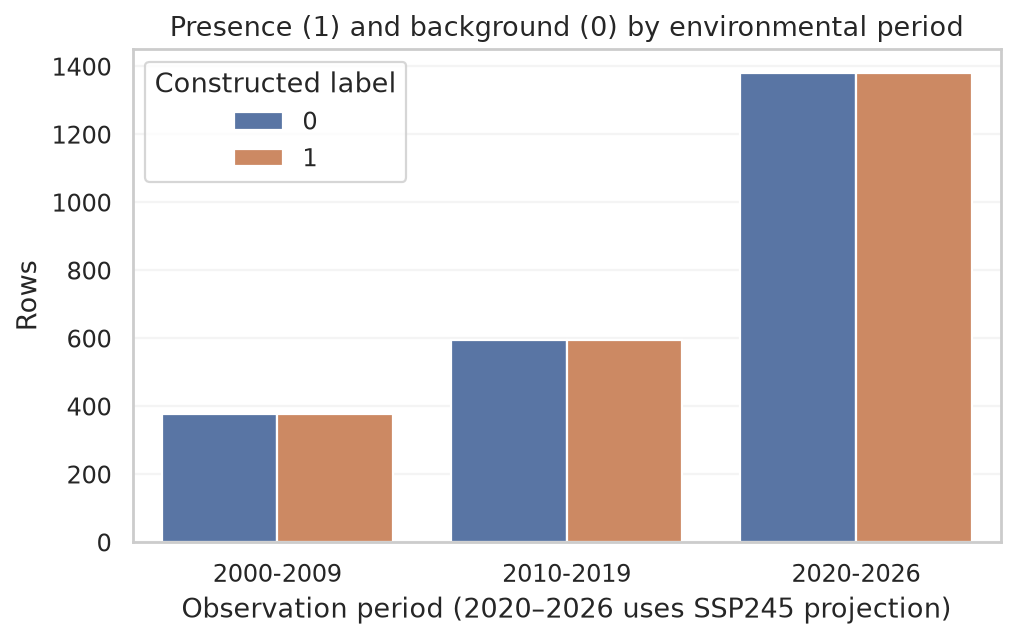

In [2]:
show_table("A_data_dictionary.csv", 12)
show_table("A_class_counts_by_period.csv", 12)
show_image("A_target_by_period.png")

## B — Missingness and data quality

Null values, infinity values and blank strings are counted separately. Repeated positive taxon/cell/period groups are reported as repeated records, not silently deduplicated.

B_environmental_missingness.csv — 764 rows; showing up to 12


,population,feature,rows,non_null,missing,missing_pct,positive_infinity,negative_infinity,missing_presence,missing_background
0,complete_population,bio_oracle__clt_sd__depthsurf,4706,0,4706,100.000000,0,0,2353,2353
1,complete_population,bio_oracle__tas_range__depthsurf,4706,0,4706,100.000000,0,0,2353,2353
2,complete_population,bio_oracle__coastline__benthic,4706,1424,3282,69.740756,0,0,964,2318
3,complete_population,bio_oracle__chl_ltmax__depthmax,4706,1835,2871,61.007225,0,0,1490,1381
4,complete_population,bio_oracle__chl_ltmax__depthmean,4706,1835,2871,61.007225,0,0,1490,1381
5,complete_population,bio_oracle__chl_ltmax__depthmin,4706,1835,2871,61.007225,0,0,1490,1381
6,complete_population,bio_oracle__chl_ltmin__depthmax,4706,1835,2871,61.007225,0,0,1490,1381
7,complete_population,bio_oracle__chl_ltmin__depthmean,4706,1835,2871,61.007225,0,0,1490,1381
8,complete_population,bio_oracle__chl_ltmin__depthmin,4706,1835,2871,61.007225,0,0,1490,1381
9,complete_population,bio_oracle__chl_max__depthmax,4706,1835,2871,61.007225,0,0,1490,1381


B_missingness_by_period_class.csv — 4,584 rows; showing up to 12


,population,period,label,feature,rows,missing,distinct_missingness_patterns
0,complete_population,2000-2009,1,bio_oracle__area__benthic,376,63,3
1,complete_population,2000-2009,1,bio_oracle__aspect__benthic,376,63,3
2,complete_population,2000-2009,1,bio_oracle__bathymetry_max__benthic,376,63,3
3,complete_population,2000-2009,1,bio_oracle__bathymetry_mean__benthic,376,63,3
4,complete_population,2000-2009,1,bio_oracle__bathymetry_min__benthic,376,63,3
5,complete_population,2000-2009,1,bio_oracle__chl_ltmax__depthmax,376,63,3
6,complete_population,2000-2009,1,bio_oracle__chl_ltmax__depthmean,376,63,3
7,complete_population,2000-2009,1,bio_oracle__chl_ltmax__depthmin,376,63,3
8,complete_population,2000-2009,1,bio_oracle__chl_ltmax__depthsurf,376,63,3
9,complete_population,2000-2009,1,bio_oracle__chl_ltmin__depthmax,376,63,3


B_blank_strings.csv — 92 rows; showing up to 12


,column,blank_non_null_strings
0,brackish,1084
1,catalogNumber,178
2,class,234
3,classid,234
4,collectionCode,289
5,collectionID,2154
6,coordinateUncertaintyInMeters,590
7,country,1982
8,countryCode,566
9,datasetID,2072


B_repeated_positive_taxon_cell_period.csv — 605 rows; showing up to 12


,population,target_taxon_key,analysis_period,grid_cell_id,source_records
0,complete_population,AphiaID:105752,2000-2009,15071,3
1,complete_population,AphiaID:105795,2010-2019,20382,2
2,complete_population,AphiaID:105795,2020-2026,20051,3
3,complete_population,AphiaID:1079115,2020-2026,14121,2
4,complete_population,AphiaID:1264645,2000-2009,15236,2
5,complete_population,AphiaID:127018,2020-2026,11123,2
6,complete_population,AphiaID:127403,2010-2019,11449,2
7,complete_population,AphiaID:127403,2020-2026,11124,3
8,complete_population,AphiaID:127403,2020-2026,20379,2
9,complete_population,AphiaID:1289433,2020-2026,14411,2


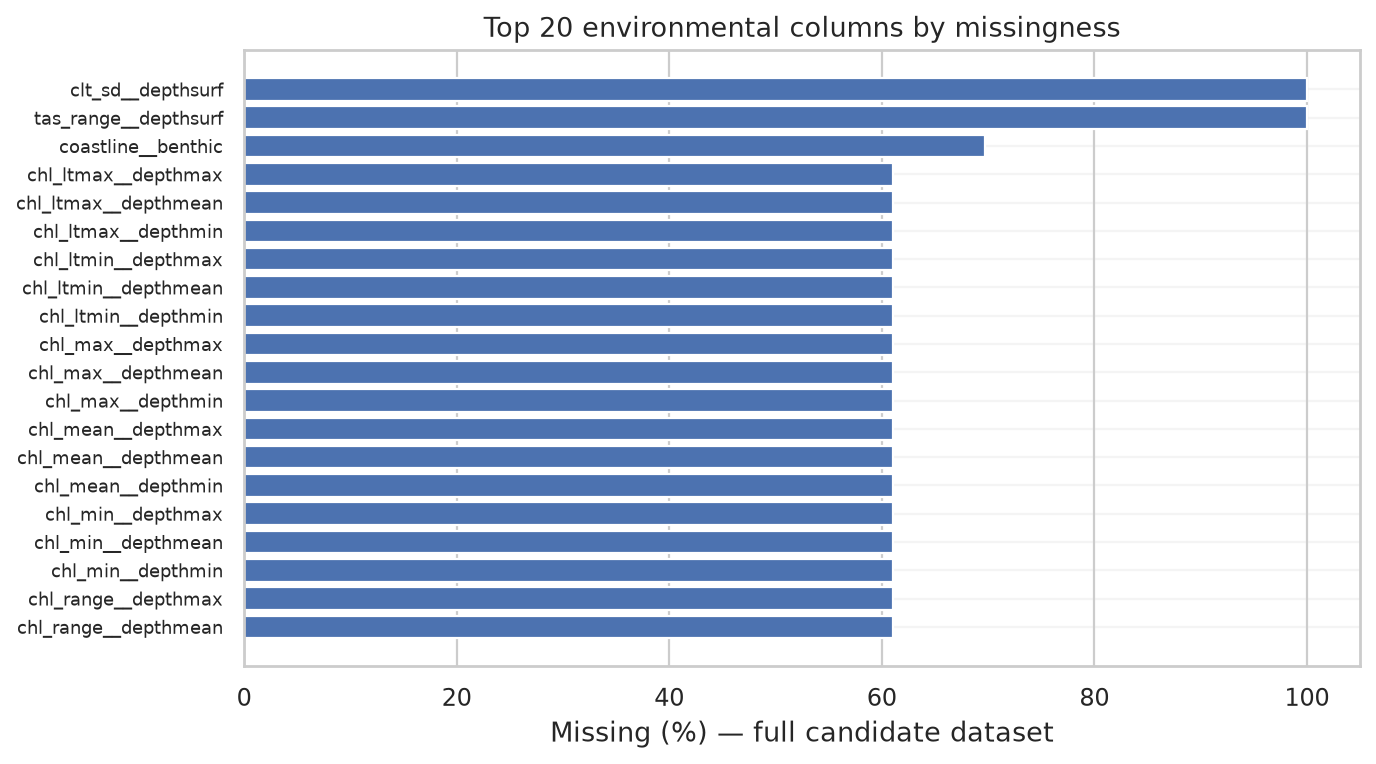

In [3]:
show_table("B_environmental_missingness.csv", 12)
show_table("B_missingness_by_period_class.csv", 12)
show_table("B_blank_strings.csv", 12)
show_table("B_repeated_positive_taxon_cell_period.csv", 12)
show_image("B_environment_missingness.png")

## C — Species and time periods

Record totals, eligible records, distinct occupied cells and active periods are separate quantities. Eligibility remains preliminary; no taxon is chosen automatically.

C_taxon_counts_distinct_cells.csv — 614 rows; showing up to 15


,target_taxon_key,original_records,distinct_occupied_cells,active_periods,distinct_cell_periods,eligible_source_records,eligible_distinct_cells,eligible_cell_periods,reported_name,records_2000-2009,distinct_cells_2000-2009,records_2010-2019,distinct_cells_2010-2019,records_2020-2026,distinct_cells_2020-2026
0,AphiaID:343936,211,71,2,96,190,59,81,Pelecanus philippensis,0,0,49,30,162,66
1,AphiaID:137206,114,65,3,75,110,61,71,Chelonia mydas,13,13,24,20,77,42
2,AphiaID:220293,83,62,2,66,80,59,63,Lepidochelys olivacea,0,0,41,35,42,31
3,AphiaID:137109,82,32,3,38,79,29,35,Stenella longirostris,2,2,19,11,61,25
4,AphiaID:137207,24,18,3,19,23,17,18,Eretmochelys imbricata,1,1,6,5,17,13
5,AphiaID:219628,22,7,3,9,22,7,9,Acanthurus leucosternon,5,1,2,2,15,6
6,AphiaID:137135,36,17,2,19,20,10,10,Chlidonias hybrida,0,0,5,4,31,15
7,AphiaID:254983,24,13,3,14,19,8,9,Tursiops aduncus,4,4,2,2,18,8
8,AphiaID:219882,18,5,3,6,17,4,5,Melichthys indicus,1,1,2,2,15,3
9,AphiaID:159582,21,8,3,10,16,6,7,Acanthurus lineatus,2,1,6,2,13,7


C_eligibility_reasons.csv — 16 rows; showing up to 20


,presence_background_label,ml_eligibility_reason,rows
0,0,missing_core_environment,27
1,0,preliminary_species_core_eligible,1729
2,0,source_cell_centre_not_marine,80
3,0,source_cell_centre_not_marine;missing_core_env...,173
4,0,unverified_species_rank,267
5,0,unverified_species_rank;missing_core_environment,6
6,0,unverified_species_rank;source_cell_centre_not...,6
7,0,unverified_species_rank;source_cell_centre_not...,65
8,1,missing_core_environment,27
9,1,preliminary_species_core_eligible,1729


C_period_class_eligibility.csv — 12 rows; showing up to 20


,analysis_period,presence_background_label,eligible_species_level_ml,rows
0,2000-2009,0,False,215
1,2000-2009,0,True,161
2,2000-2009,1,False,215
3,2000-2009,1,True,161
4,2010-2019,0,False,153
5,2010-2019,0,True,443
6,2010-2019,1,False,153
7,2010-2019,1,True,443
8,2020-2026,0,False,256
9,2020-2026,0,True,1125


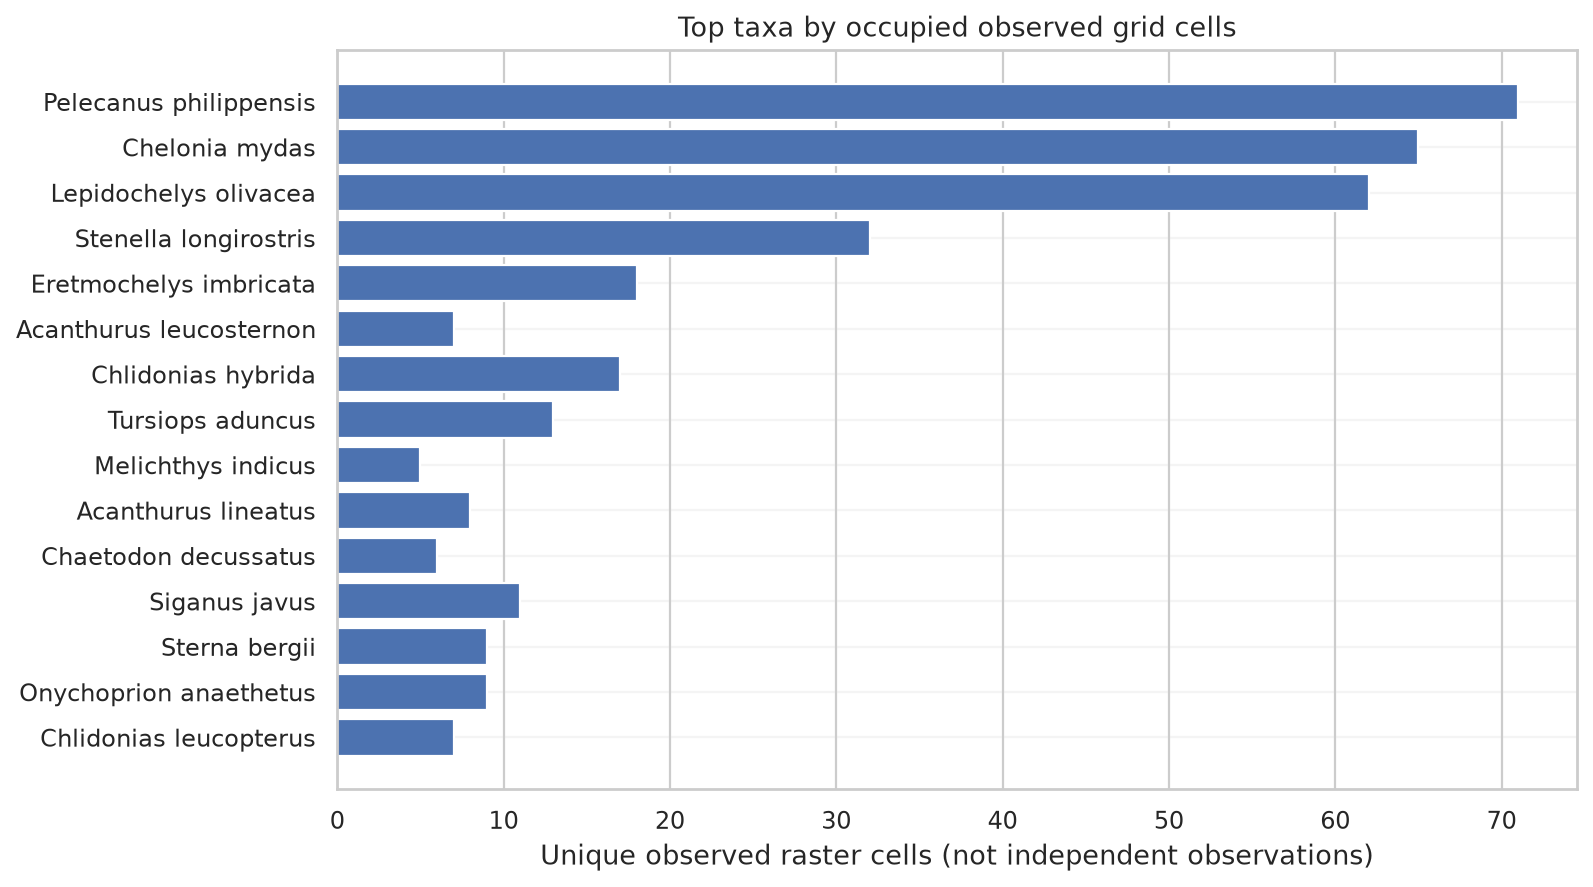

In [4]:
show_table("C_taxon_counts_distinct_cells.csv", 15)
show_table("C_eligibility_reasons.csv", 20)
show_table("C_period_class_eligibility.csv", 20)
show_image("C_top_taxa_cells.png")

## D — Environmental distributions

The overall histograms compare classes; period-stratified boxplots show class distributions by environmental period. Summary tables include medians, quartiles, range and descriptive IQR flags. No outliers are removed.

D_core_overall_class_stats.csv — 24 rows; showing up to 20


,population,label,feature,n,mean,median,std,q25,q75,min,max
0,complete_population,0,bio_oracle__thetao_mean__depthsurf,2353,28.998958,29.053771,0.260607,28.860507,29.180262,27.555835,29.587179
1,complete_population,0,bio_oracle__so_mean__depthsurf,2353,33.991685,34.122311,0.491299,33.549612,34.401474,32.396631,34.811646
2,complete_population,0,bio_oracle__o2_mean__depthsurf,2353,200.735742,200.597079,0.984014,200.051008,201.377475,198.211291,205.107923
3,complete_population,0,bio_oracle__chl_mean__depthsurf,2353,0.169239,0.136340,0.099748,0.127816,0.165076,0.110450,1.052550
4,complete_population,0,bio_oracle__ph_mean__depthsurf,2353,8.035177,8.030830,0.011952,8.026569,8.041899,8.007108,8.065403
5,complete_population,0,bio_oracle__bathymetry_mean__benthic,2353,-3311.950468,-3771.611084,1262.108239,-4147.500000,-3174.750000,-4451.861328,-0.027778
6,complete_population,1,bio_oracle__thetao_mean__depthsurf,2082,28.845126,28.837890,0.313531,28.583747,29.099782,28.093394,29.602480
7,complete_population,1,bio_oracle__so_mean__depthsurf,2082,33.685424,33.850956,0.396122,33.256607,33.964041,32.755903,34.668863
8,complete_population,1,bio_oracle__o2_mean__depthsurf,2082,201.943752,202.106932,1.013154,202.021543,202.578952,198.444447,203.702961
9,complete_population,1,bio_oracle__chl_mean__depthsurf,2082,0.251535,0.270392,0.052113,0.184916,0.293473,0.116508,0.354791


D_core_by_period_class_stats.csv — 72 rows; showing up to 20


,population,period,label,feature,n,mean,median,std,q25,q75,min,max
0,complete_population,2000-2009,0,bio_oracle__thetao_mean__depthsurf,376,28.724228,28.765199,0.228769,28.696418,28.860611,27.555835,29.054207
1,complete_population,2000-2009,0,bio_oracle__so_mean__depthsurf,376,34.026121,34.121523,0.503915,33.590266,34.454504,32.396631,34.811646
2,complete_population,2000-2009,0,bio_oracle__o2_mean__depthsurf,376,201.481492,201.253111,0.964575,200.677336,202.028942,200.251913,205.107923
3,complete_population,2000-2009,0,bio_oracle__chl_mean__depthsurf,376,0.176380,0.144080,0.105278,0.131541,0.163917,0.111039,0.983498
4,complete_population,2000-2009,0,bio_oracle__ph_mean__depthsurf,376,8.056902,8.057302,0.004856,8.054356,8.060952,8.036207,8.065403
5,complete_population,2000-2009,0,bio_oracle__bathymetry_mean__benthic,376,-3372.571954,-3806.152710,1228.508287,-4146.847168,-3413.861145,-4451.861328,-0.027778
6,complete_population,2000-2009,1,bio_oracle__thetao_mean__depthsurf,313,28.745249,28.837890,0.170703,28.713375,28.837890,28.093394,29.096255
7,complete_population,2000-2009,1,bio_oracle__so_mean__depthsurf,313,33.920384,34.082250,0.332171,33.972949,34.082250,32.755903,34.668863
8,complete_population,2000-2009,1,bio_oracle__o2_mean__depthsurf,313,202.369710,202.578952,0.763980,202.477446,202.738798,200.463174,203.702961
9,complete_population,2000-2009,1,bio_oracle__chl_mean__depthsurf,313,0.260437,0.303549,0.065038,0.204453,0.307744,0.119785,0.313392


D_core_IQR_flags.csv — 24 rows; showing up to 20


,population,label,feature,non_null,iqr_flagged_rows_descriptive_only
0,complete_population,0,bio_oracle__thetao_mean__depthsurf,2353,67
1,complete_population,0,bio_oracle__so_mean__depthsurf,2353,0
2,complete_population,0,bio_oracle__o2_mean__depthsurf,2353,18
3,complete_population,0,bio_oracle__chl_mean__depthsurf,2353,312
4,complete_population,0,bio_oracle__ph_mean__depthsurf,2353,4
5,complete_population,0,bio_oracle__bathymetry_mean__benthic,2353,310
6,complete_population,1,bio_oracle__thetao_mean__depthsurf,2082,0
7,complete_population,1,bio_oracle__so_mean__depthsurf,2082,0
8,complete_population,1,bio_oracle__o2_mean__depthsurf,2082,294
9,complete_population,1,bio_oracle__chl_mean__depthsurf,2082,0


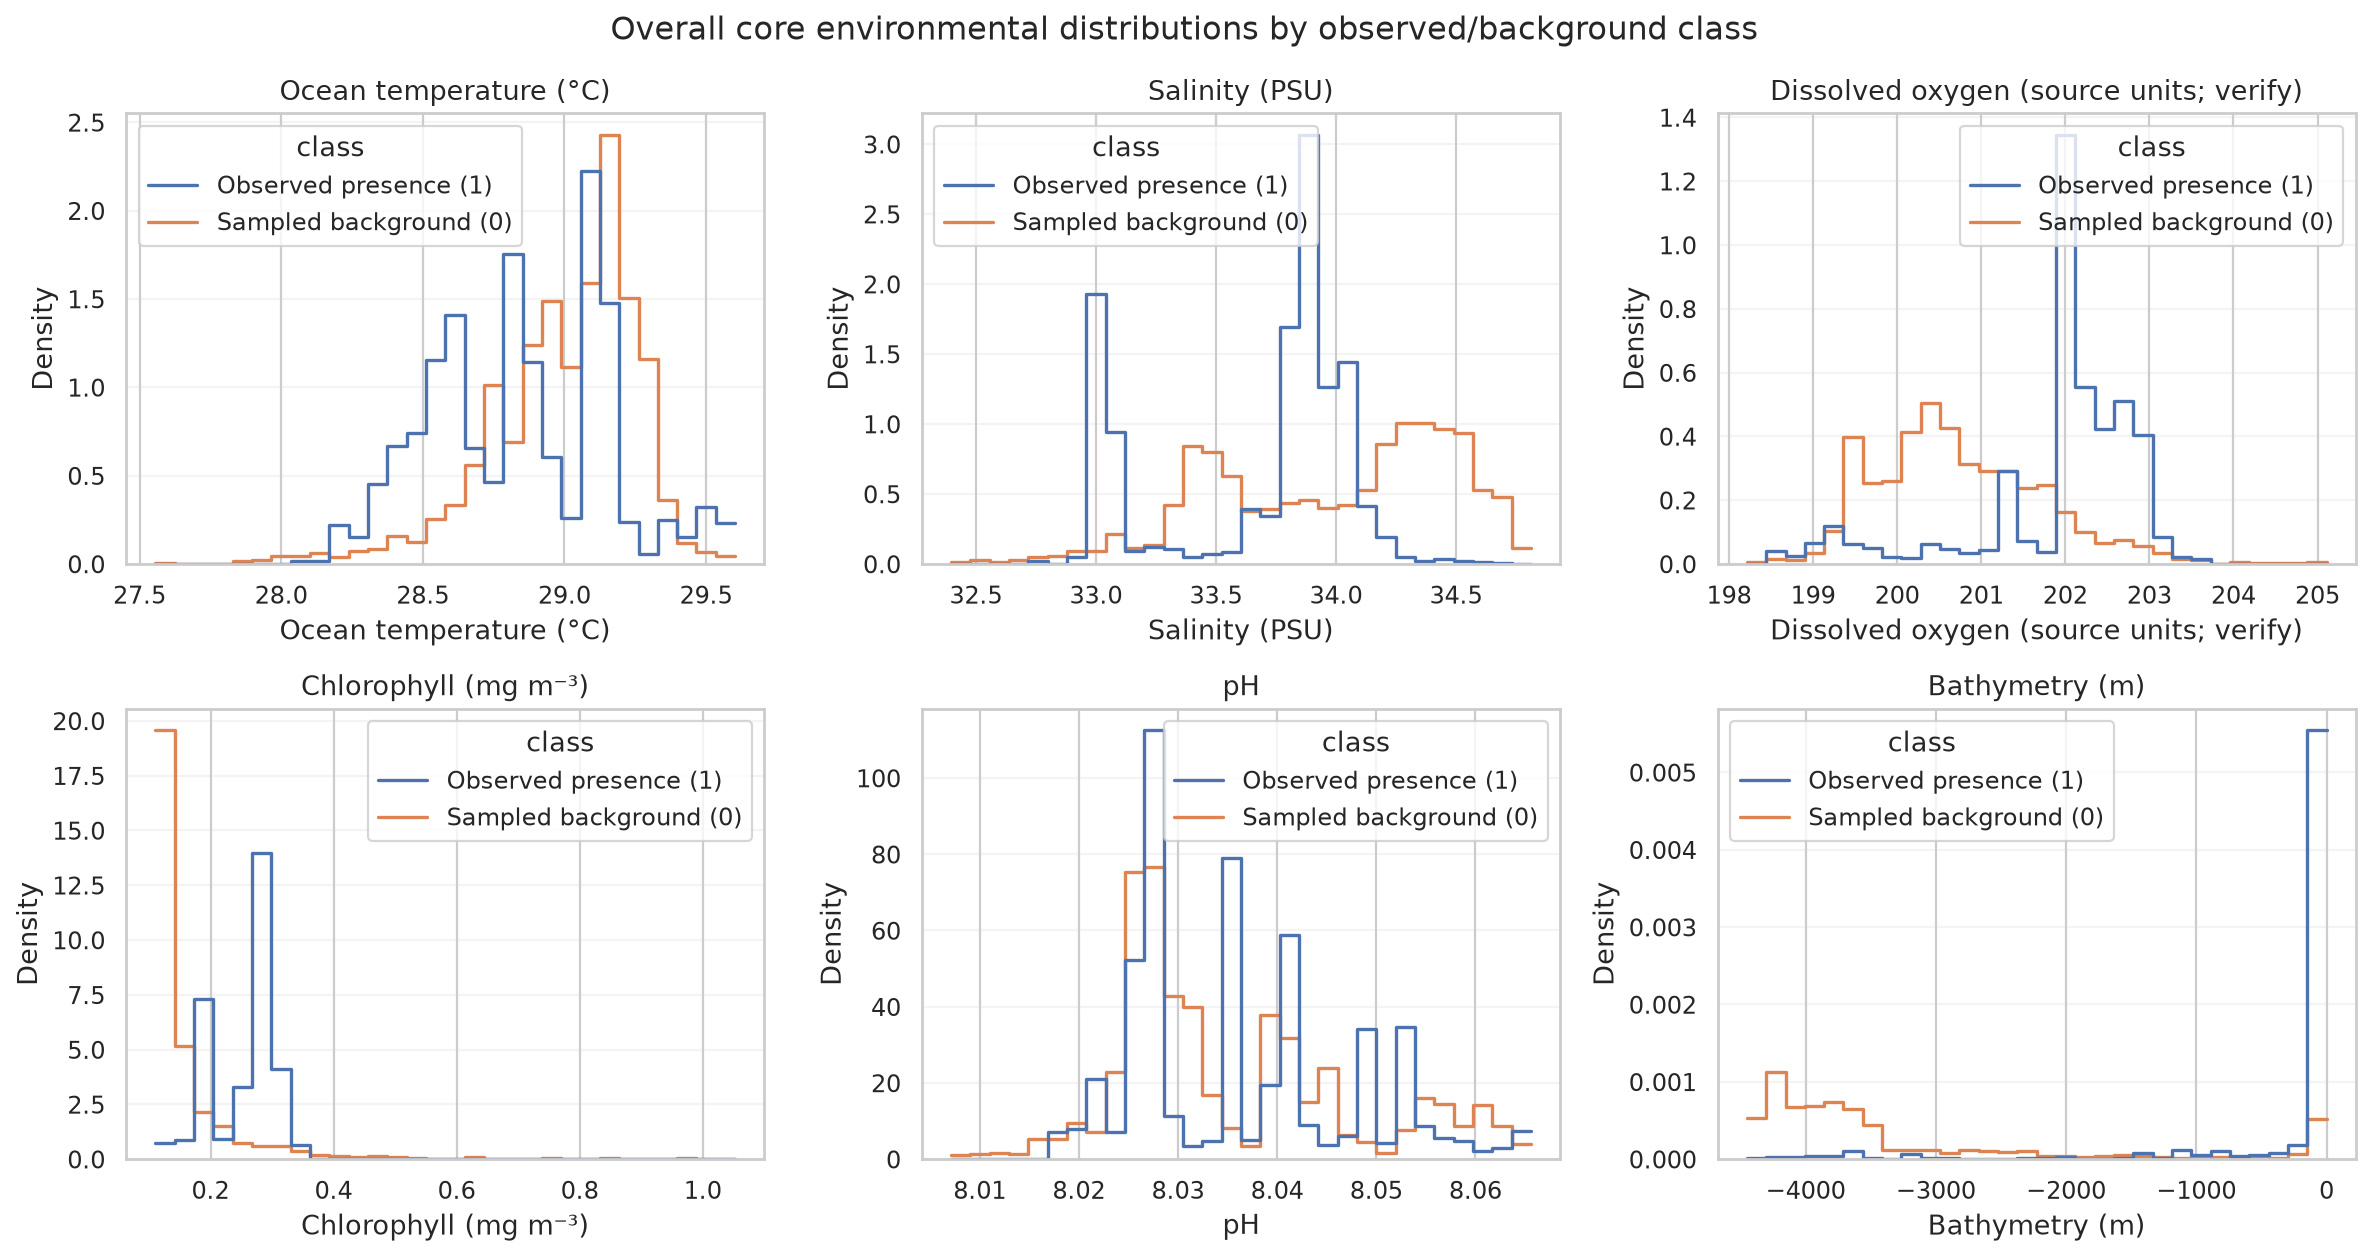

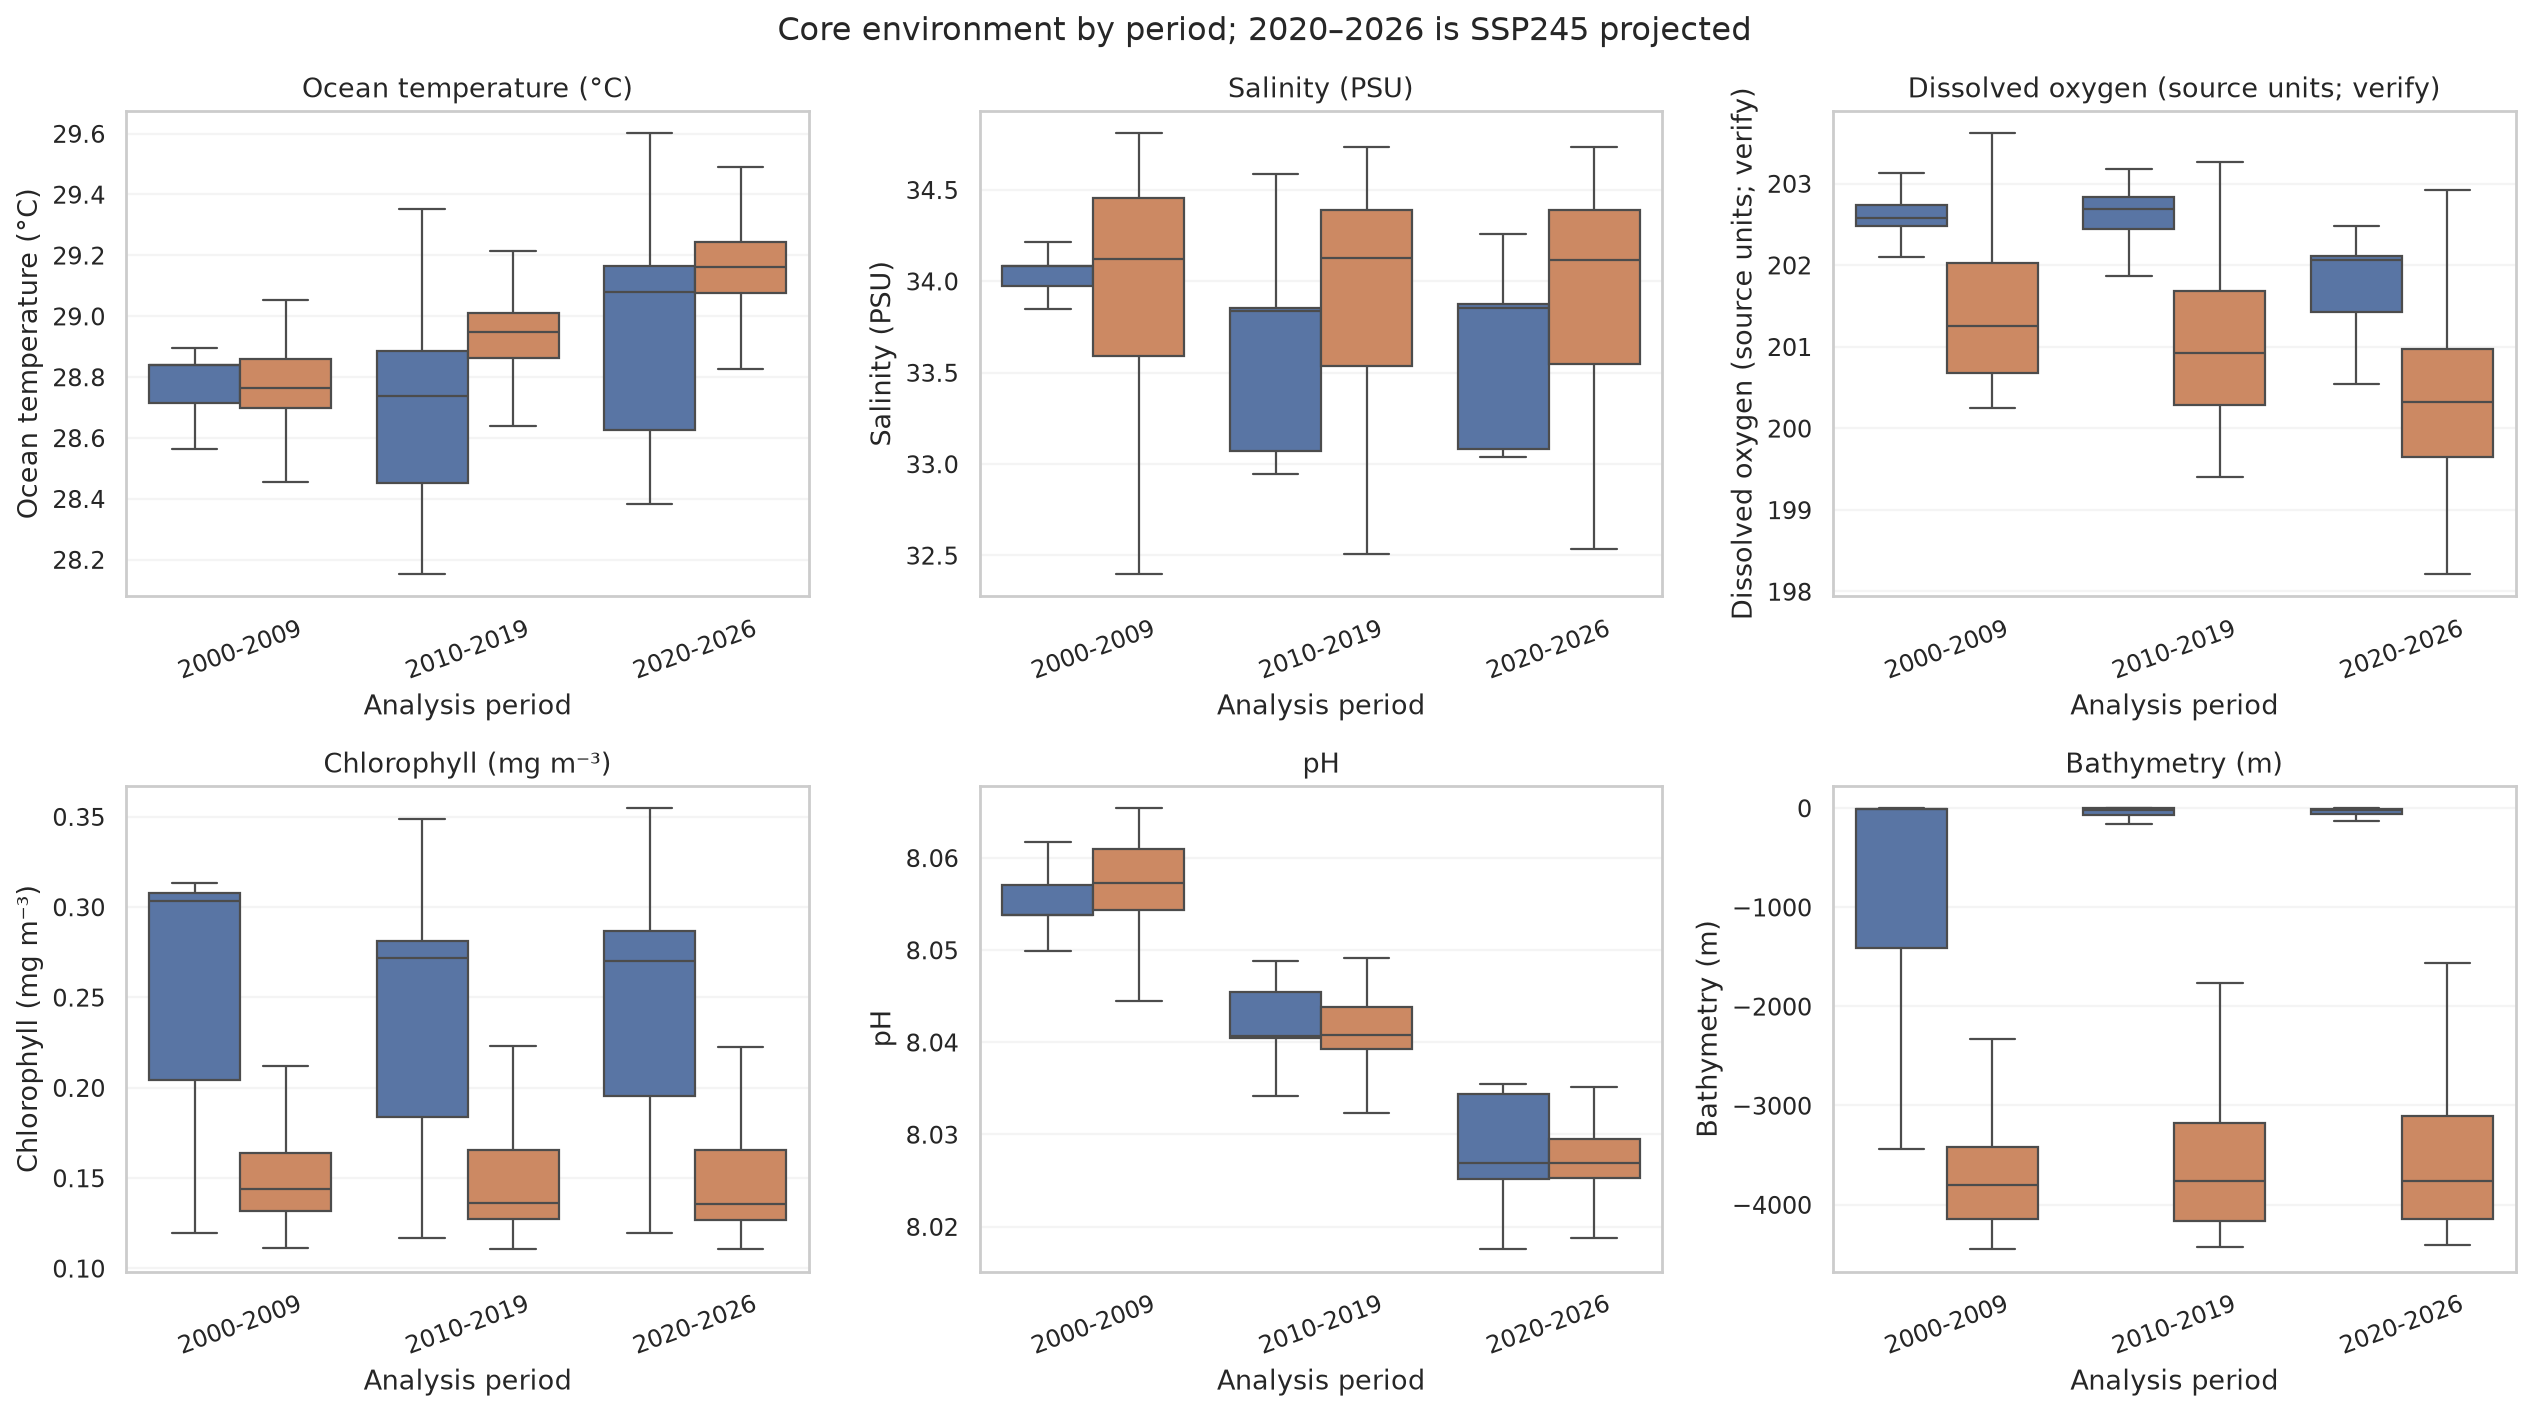

In [5]:
show_table("D_core_overall_class_stats.csv", 20)
show_table("D_core_by_period_class_stats.csv", 20)
show_table("D_core_IQR_flags.csv", 20)
show_image("D_core_distributions_by_class.png")
show_image("D_core_distributions_by_period.png")

## E — Correlation and feature redundancy

The feature screen covers all 382 definitions, with period-specific quarantine metadata. Correlations use unique grid-cell/period profiles so repeated occurrence records do not inflate sample counts. High correlations are investigation candidates, not feature-removal decisions.

E_feature_profile_screen.csv — 764 rows; showing up to 15


,population,feature,unique_cell_period_profiles,valid_profiles,missing_profiles,missing_pct_profiles,distinct_nonnull_values,constant_or_empty,quarantined_periods_in_manifest,quarantine_reasons_in_manifest
0,complete_population,bio_oracle__area__benthic,2833,2775,58,2.047300,178,False,NaN,{}
1,complete_population,bio_oracle__aspect__benthic,2833,2775,58,2.047300,2671,False,NaN,{}
2,complete_population,bio_oracle__bathymetry_max__benthic,2833,2775,58,2.047300,1415,False,NaN,{}
3,complete_population,bio_oracle__bathymetry_mean__benthic,2833,2775,58,2.047300,2578,False,NaN,{}
4,complete_population,bio_oracle__bathymetry_min__benthic,2833,2775,58,2.047300,1376,False,NaN,{}
5,complete_population,bio_oracle__chl_ltmax__depthmax,2833,1195,1638,57.818567,601,False,NaN,{}
6,complete_population,bio_oracle__chl_ltmax__depthmean,2833,1195,1638,57.818567,613,False,NaN,{}
7,complete_population,bio_oracle__chl_ltmax__depthmin,2833,1195,1638,57.818567,614,False,NaN,{}
8,complete_population,bio_oracle__chl_ltmax__depthsurf,2833,2775,58,2.047300,2775,False,NaN,{}
9,complete_population,bio_oracle__chl_ltmin__depthmax,2833,1195,1638,57.818567,573,False,NaN,{}


E_redundant_feature_pairs_by_period.csv — 3,602 rows; showing up to 15


,population,period,feature_a,feature_b,spearman_rho,paired_valid_profiles,unique_cell_period_profiles
0,complete_population,2010-2019,bio_oracle__po4_max__depthsurf,bio_oracle__po4_range__depthsurf,0.999998,752,767
1,eligible_species_subset,2010-2019,bio_oracle__po4_max__depthsurf,bio_oracle__po4_range__depthsurf,0.999998,577,577
2,complete_population,2000-2009,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999994,443,446
3,complete_population,2010-2019,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999992,752,767
4,eligible_species_subset,2010-2019,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999990,577,577
5,complete_population,2000-2009,bio_oracle__po4_max__depthsurf,bio_oracle__po4_range__depthsurf,0.999990,443,446
6,eligible_species_subset,2000-2009,bio_oracle__po4_max__depthsurf,bio_oracle__po4_range__depthsurf,0.999988,182,182
7,eligible_species_subset,2000-2009,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999986,182,182
8,complete_population,2020-2026,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999956,1580,1620
9,eligible_species_subset,2020-2026,bio_oracle__no3_max__depthsurf,bio_oracle__no3_range__depthsurf,0.999953,1314,1314


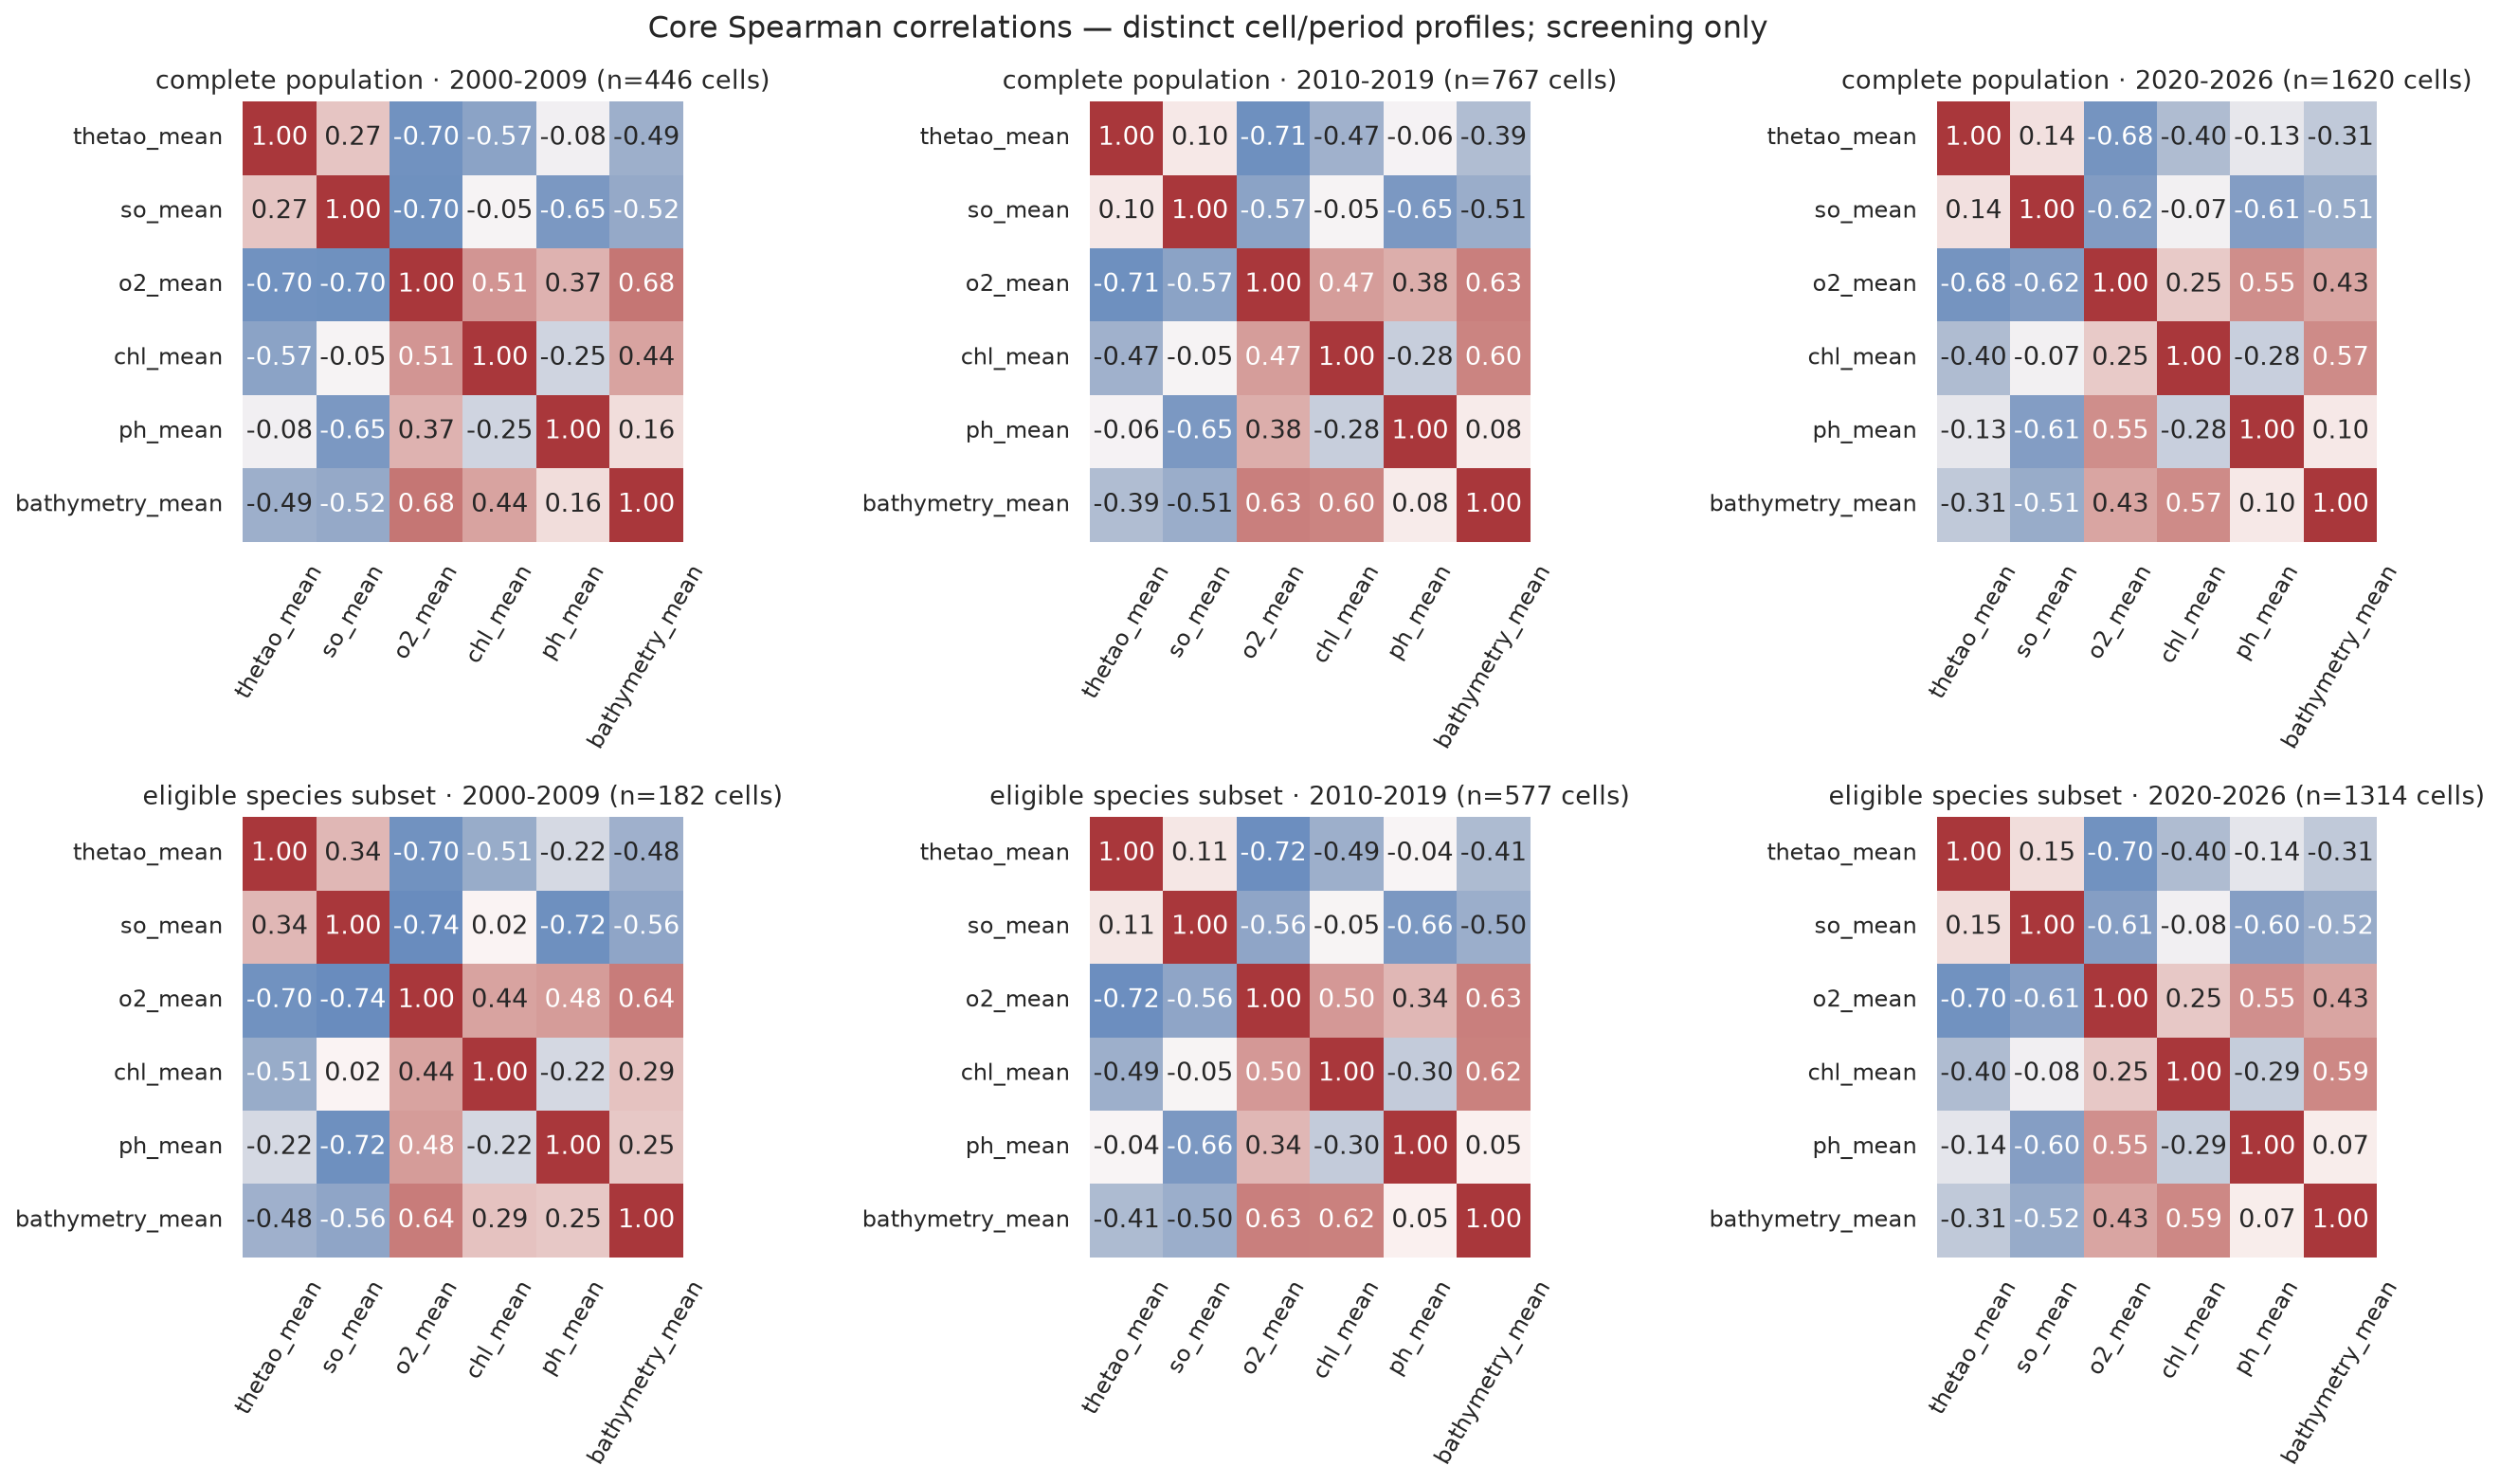

In [6]:
show_table("E_feature_profile_screen.csv", 15)
show_table("E_redundant_feature_pairs_by_period.csv", 15)
show_image("E_core_spearman_by_period.png")

## F — Spatial sampling diagnostics

Maps are location diagnostics, not habitat-suitability predictions. Coast-distance summaries use grid-cell centres and the 2017 GSHHG coastline. Background-to-presence distances compare the same taxon within the same period. These measures do not quantify survey effort.

F_background_distance_to_same_taxon_presence.csv — 4,082 rows; showing up to 12


,population,period,taxon_key,sample_id,background_cell_id,nearest_presence_km
0,complete_population,2000-2009,AphiaID:105752,background:1733,12310,262.126723
1,complete_population,2000-2009,AphiaID:105752,background:6656,22377,353.965293
2,complete_population,2000-2009,AphiaID:105752,background:11925,14206,220.506082
3,complete_population,2000-2009,AphiaID:1264645,background:3613,21239,401.009402
4,complete_population,2000-2009,AphiaID:1264645,background:18037,12865,580.348400
5,complete_population,2000-2009,AphiaID:129784,background:1693,28835,275.888987
6,complete_population,2000-2009,AphiaID:129832,background:3709,8920,694.338327
7,complete_population,2000-2009,AphiaID:130140,background:3595,23349,114.106247
8,complete_population,2000-2009,AphiaID:130344,background:21128,12700,618.257318
9,complete_population,2000-2009,AphiaID:130344,background:22211,27942,117.199109


F_observation_records_per_grid_cell_period.csv — 6,813 rows; showing up to 12


,population,label,period,taxon_key,grid_cell_id,records_in_cell_period,distance_to_coast_median_km,bathymetry_median_m
0,complete_population,0,2000-2009,AphiaID:105752,12310,1,42.847218,-3998.083252
1,complete_population,0,2000-2009,AphiaID:105752,14206,1,136.168011,-2218.861084
2,complete_population,0,2000-2009,AphiaID:105752,22377,1,121.465746,-3825.388916
3,complete_population,0,2000-2009,AphiaID:1264645,12865,1,354.063337,-3890.444336
4,complete_population,0,2000-2009,AphiaID:1264645,21239,1,186.142420,-3713.277832
5,complete_population,0,2000-2009,AphiaID:129784,28835,1,347.749142,-3523.694336
6,complete_population,0,2000-2009,AphiaID:129832,8920,1,298.339457,-2639.083252
7,complete_population,0,2000-2009,AphiaID:130140,23349,1,58.508458,-3659.083252
8,complete_population,0,2000-2009,AphiaID:130344,12700,1,355.127509,-3901.000000
9,complete_population,0,2000-2009,AphiaID:130344,27942,1,1.830494,-5.861111


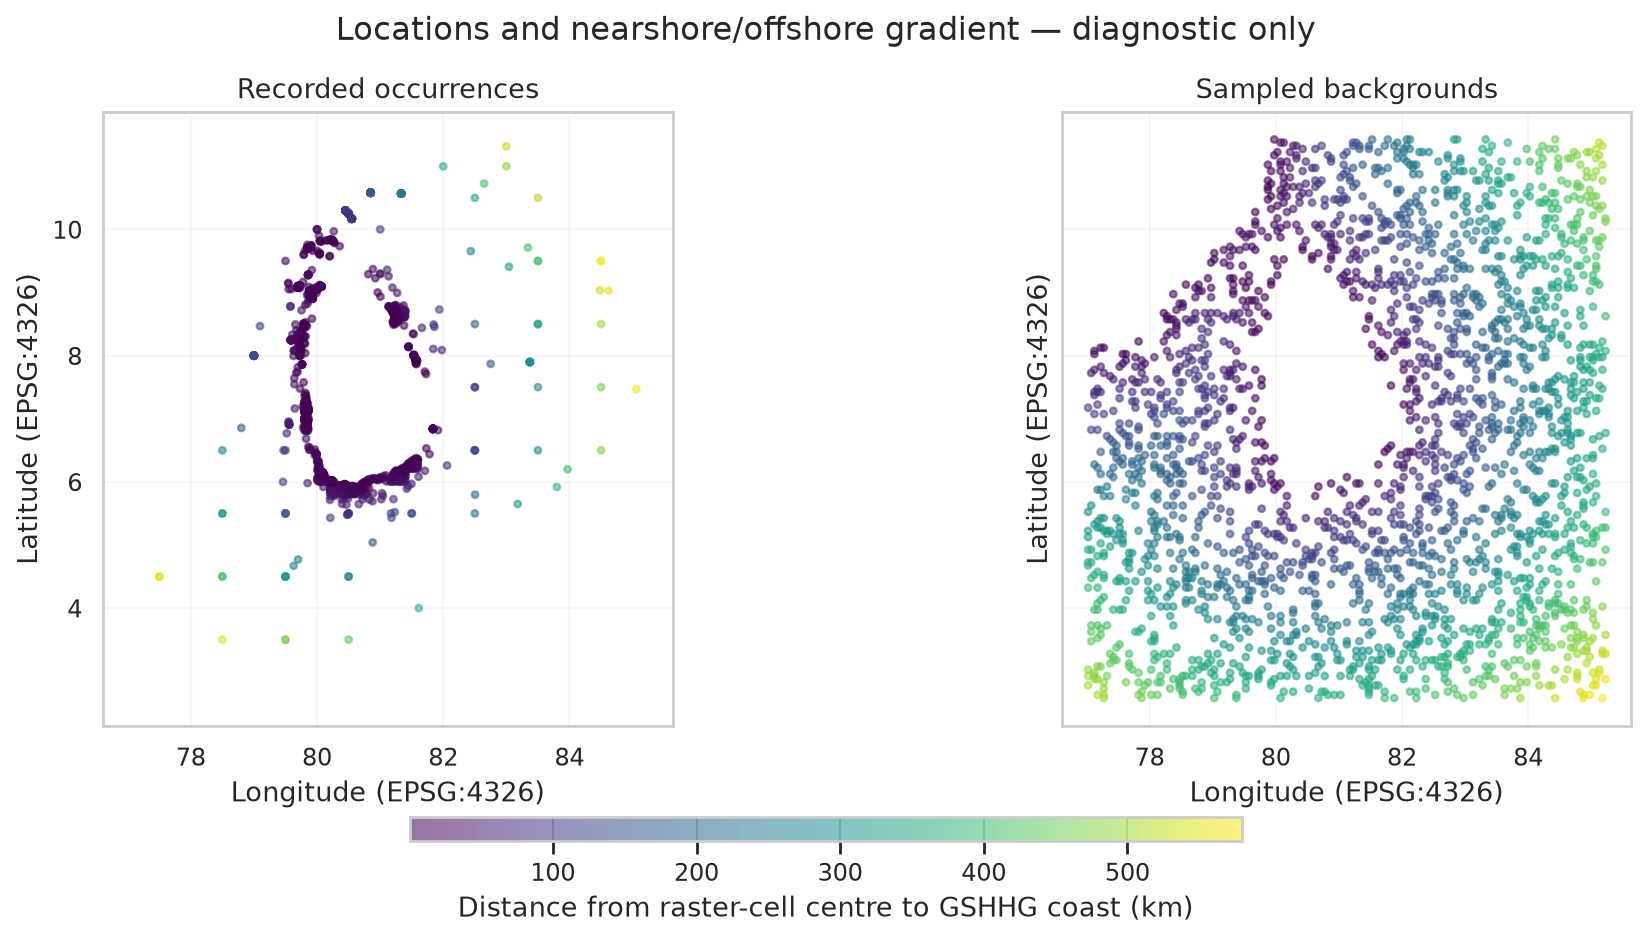

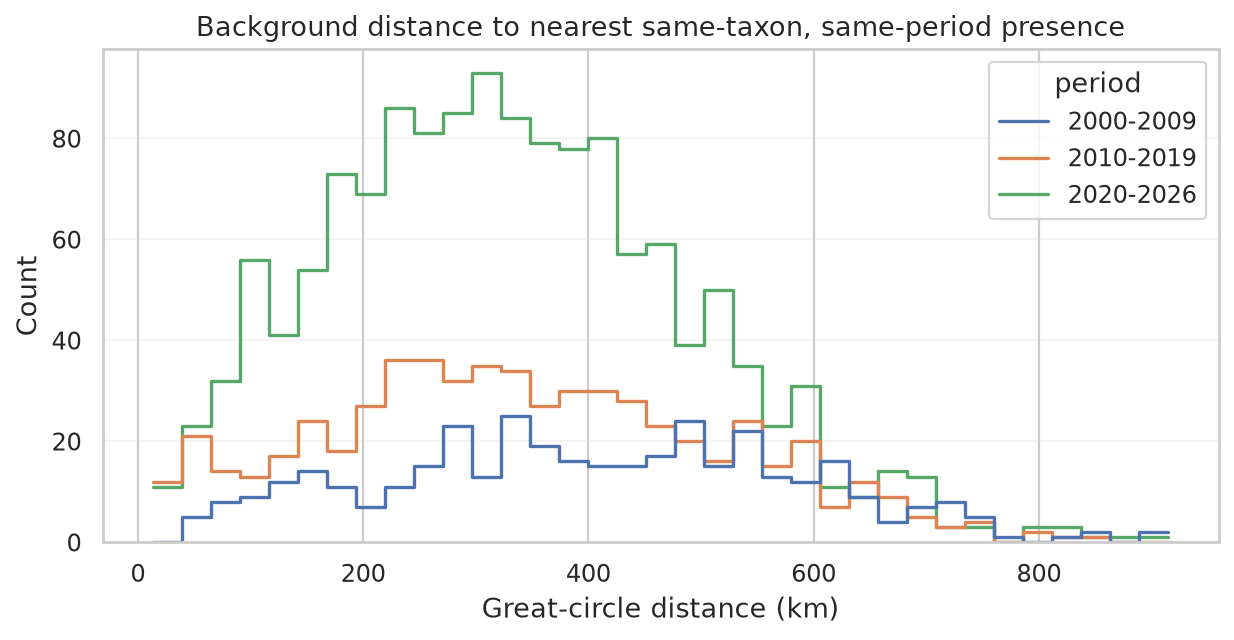

In [7]:
show_table("F_background_distance_to_same_taxon_presence.csv", 12)
show_table("F_observation_records_per_grid_cell_period.csv", 12)
show_image("F_spatial_presence_background.png")
show_image("F_nearest_presence_distances.png")

## Findings and limits

Source quarantine fields remain present. The large bathymetry and coastline-distance contrasts between positives and sampled backgrounds require review as possible domain and sampling-design confounding. Feature families with strong within-period correlation, particularly closely related summary statistics, are candidates for later feature-selection investigation.

Before modelling, the group still needs to agree focal taxa, accessible marine sampling domain, treatment of missing/quarantined features, and cell-grouped spatial validation. Do not infer absence from unsampled locations, occurrence probabilities from the balanced class ratio, or model readiness from successful EDA execution.

In [9]:
summary = json.loads(SUMMARY.read_text(encoding="utf-8"))
print("Source fingerprint unchanged:", summary["all_protected_inputs_unchanged"])
print("Input:", summary["source"]["path"])
print("Shape:", summary["source"]["shape"])
print("Environmental features:", summary["environmental_features"])
print("Eligible rows:", summary["eligible_species_subset_rows"])
print("CSV tables:", len(summary["artifacts"]["tables"]))
print("Figures:", len(summary["artifacts"]["figures"]))
display(Markdown(REPORT.read_text(encoding="utf-8")))

Source fingerprint unchanged: True
Input: data/interim/pseudo_absence/presence_background_candidates.parquet
Shape: [4706, 527]
Environmental features: 382
Eligible rows: 3458
CSV tables: 16
Figures: 8


# OCEAVERA — Exploratory Data Analysis (Sections A–F)

**Status:** Descriptive EDA completed on the frozen candidate table. This is not a target, species, predictor or modelling approval.

## Input and population

- Source: `data/interim/pseudo_absence/presence_background_candidates.parquet` (9,412,505 bytes)
- SHA-256: `234177bf3641856cdd10b425f2da957a27210f876d31092ba715a53cee7a429f` (identical after execution)
- Shape/CRS/geometry: **4,706 × 527**, EPSG:4326, Point
- Environmental definitions: **382**; all were retained in the input.
- Preliminary species-level eligible subset: **3,458 rows** (1,729 positives, 1,729 sampled backgrounds).

A positive is a recorded OBIS occurrence. A background row is a sampled marine cell and is **not** a verified absence. Repeated records may share a grid cell.

## Period and class counts

| population | analysis_period | presence_background_label | rows |
| --- | --- | --- | --- |
| complete_population | 2000-2009 | 0 | 376 |
| complete_population | 2000-2009 | 1 | 376 |
| complete_population | 2010-2019 | 0 | 596 |
| complete_population | 2010-2019 | 1 | 596 |
| complete_population | 2020-2026 | 0 | 1381 |
| complete_population | 2020-2026 | 1 | 1381 |
| eligible_species_subset | 2000-2009 | 0 | 161 |
| eligible_species_subset | 2000-2009 | 1 | 161 |
| eligible_species_subset | 2010-2019 | 0 | 443 |
| eligible_species_subset | 2010-2019 | 1 | 443 |
| eligible_species_subset | 2020-2026 | 0 | 1125 |
| eligible_species_subset | 2020-2026 | 1 | 1125 |

## Taxa and environmental completeness

- Positive taxon keys: **614** (eligible-positive taxon keys: **441**).
- Distinct positive grid cells: **362**; distinct cell-periods: **480**.
- Repeated positive taxon/cell/period groups: **331**, covering **1,107** records (776 beyond one per group).
- Blank string values occur **99,424** times across 92 source/metadata columns; null and blank counts remain separate.
- Environmental fields fully populated in complete population: **0 / 382**; completely empty: **2**.
- Eligible subset fully populated features: **303 / 382**; infinities found: **0**.

### Taxonomic eligibility reasons

| presence_background_label | ml_eligibility_reason | rows |
| --- | --- | --- |
| 0 | missing_core_environment | 27 |
| 0 | preliminary_species_core_eligible | 1729 |
| 0 | source_cell_centre_not_marine | 80 |
| 0 | source_cell_centre_not_marine;missing_core_environment | 173 |
| 0 | unverified_species_rank | 267 |
| 0 | unverified_species_rank;missing_core_environment | 6 |
| 0 | unverified_species_rank;source_cell_centre_not_marine | 6 |
| 0 | unverified_species_rank;source_cell_centre_not_marine;missing_core_environment | 65 |
| 1 | missing_core_environment | 27 |
| 1 | preliminary_species_core_eligible | 1729 |
| 1 | source_cell_centre_not_marine | 80 |
| 1 | source_cell_centre_not_marine;missing_core_environment | 173 |
| 1 | unverified_species_rank | 267 |
| 1 | unverified_species_rank;missing_core_environment | 6 |
| 1 | unverified_species_rank;source_cell_centre_not_marine | 6 |
| 1 | unverified_species_rank;source_cell_centre_not_marine;missing_core_environment | 65 |

### Species with broad eligible cell support for review

| target_taxon_key | reported_name | eligible_source_records | eligible_distinct_cells | eligible_cell_periods | active_periods |
| --- | --- | --- | --- | --- | --- |
| AphiaID:137206 | Chelonia mydas | 110 | 61 | 71 | 3 |
| AphiaID:343936 | Pelecanus philippensis | 190 | 59 | 81 | 2 |
| AphiaID:220293 | Lepidochelys olivacea | 80 | 59 | 63 | 2 |
| AphiaID:137109 | Stenella longirostris | 79 | 29 | 35 | 3 |
| AphiaID:137207 | Eretmochelys imbricata | 23 | 17 | 18 | 3 |
| AphiaID:137135 | Chlidonias hybrida | 20 | 10 | 10 | 2 |
| AphiaID:159115 | Egretta garzetta | 12 | 10 | 10 | 3 |
| AphiaID:567792 | Onychoprion anaethetus | 15 | 9 | 9 | 2 |
| AphiaID:137090 | Balaenoptera musculus | 11 | 9 | 9 | 3 |
| AphiaID:254983 | Tursiops aduncus | 19 | 8 | 9 | 3 |

These are candidates for group review, not an automatic focal-species choice. Some taxa and records may need ecological, taxonomic and observation-quality assessment.

### Taxon overview (first 15 by eligible record support)

| target_taxon_key | reported_name | original_records | distinct_occupied_cells | eligible_source_records | eligible_distinct_cells | active_periods |
| --- | --- | --- | --- | --- | --- | --- |
| AphiaID:343936 | Pelecanus philippensis | 211 | 71 | 190 | 59 | 2 |
| AphiaID:137206 | Chelonia mydas | 114 | 65 | 110 | 61 | 3 |
| AphiaID:220293 | Lepidochelys olivacea | 83 | 62 | 80 | 59 | 2 |
| AphiaID:137109 | Stenella longirostris | 82 | 32 | 79 | 29 | 3 |
| AphiaID:137207 | Eretmochelys imbricata | 24 | 18 | 23 | 17 | 3 |
| AphiaID:219628 | Acanthurus leucosternon | 22 | 7 | 22 | 7 | 3 |
| AphiaID:137135 | Chlidonias hybrida | 36 | 17 | 20 | 10 | 2 |
| AphiaID:254983 | Tursiops aduncus | 24 | 13 | 19 | 8 | 3 |
| AphiaID:219882 | Melichthys indicus | 18 | 5 | 17 | 4 | 3 |
| AphiaID:159582 | Acanthurus lineatus | 21 | 8 | 16 | 6 | 3 |
| AphiaID:273333 | Chaetodon decussatus | 16 | 6 | 16 | 6 | 3 |
| AphiaID:273914 | Siganus javus | 19 | 11 | 15 | 7 | 2 |
| AphiaID:212606 | Sterna bergii | 17 | 9 | 15 | 8 | 2 |
| AphiaID:567792 | Onychoprion anaethetus | 15 | 9 | 15 | 9 | 2 |
| AphiaID:137136 | Chlidonias leucopterus | 16 | 7 | 15 | 6 | 2 |

## Core environment

Values below are descriptive; units follow source/catalogue conventions. In particular, the oxygen unit notation requires interpretation.

| population | label | feature | n | median | mean | q25 | q75 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| complete_population | 0 | bio_oracle__thetao_mean__depthsurf | 2353 | 29.05377101335928 | 28.998957988603475 | 28.860507456247387 | 29.18026199868728 |
| complete_population | 0 | bio_oracle__so_mean__depthsurf | 2353 | 34.12231140348357 | 33.99168526828917 | 33.54961226565196 | 34.4014740480167 |
| complete_population | 0 | bio_oracle__o2_mean__depthsurf | 2353 | 200.5970786024218 | 200.7357423886736 | 200.0510079262801 | 201.37747454924488 |
| complete_population | 0 | bio_oracle__chl_mean__depthsurf | 2353 | 0.1363398472133075 | 0.1692386893966844 | 0.1278160516682024 | 0.1650759522383309 |
| complete_population | 0 | bio_oracle__ph_mean__depthsurf | 2353 | 8.030829730547339 | 8.035177074641343 | 8.0265694472735 | 8.041898519582627 |
| complete_population | 0 | bio_oracle__bathymetry_mean__benthic | 2353 | -3771.611083984375 | -3311.950467540561 | -4147.5 | -3174.75 |
| complete_population | 1 | bio_oracle__thetao_mean__depthsurf | 2082 | 28.83789008300181 | 28.84512560028925 | 28.58374728806698 | 29.099781714697528 |
| complete_population | 1 | bio_oracle__so_mean__depthsurf | 2082 | 33.85095631337939 | 33.68542415132127 | 33.25660728949061 | 33.96404097797454 |
| complete_population | 1 | bio_oracle__o2_mean__depthsurf | 2082 | 202.10693231077803 | 201.9437516204232 | 202.0215429843423 | 202.57895153369165 |
| complete_population | 1 | bio_oracle__chl_mean__depthsurf | 2082 | 0.2703917021091242 | 0.2515352701624006 | 0.1849159219555895 | 0.2934726085155755 |
| complete_population | 1 | bio_oracle__ph_mean__depthsurf | 2082 | 8.034917055100173 | 8.035917300396282 | 8.026828579552875 | 8.041038405442013 |
| complete_population | 1 | bio_oracle__bathymetry_mean__benthic | 2082 | -15.88888931274414 | -325.8648067581665 | -68.11111450195312 | -7.0 |
| eligible_species_subset | 0 | bio_oracle__thetao_mean__depthsurf | 1729 | 29.085204584748688 | 29.023804547559106 | 28.89502977463847 | 29.191283744931823 |
| eligible_species_subset | 0 | bio_oracle__so_mean__depthsurf | 1729 | 34.13453690149004 | 33.9965156665894 | 33.548281571649426 | 34.40276437976717 |
| eligible_species_subset | 0 | bio_oracle__o2_mean__depthsurf | 1729 | 200.54166504551588 | 200.6641159296953 | 199.96588365585043 | 201.31014307830424 |
| eligible_species_subset | 0 | bio_oracle__chl_mean__depthsurf | 1729 | 0.1361356116084944 | 0.1677868403327348 | 0.1273973773523253 | 0.1657501172377104 |
| eligible_species_subset | 0 | bio_oracle__ph_mean__depthsurf | 1729 | 8.029707700075246 | 8.033204184747348 | 8.02617155527455 | 8.039877933075768 |
| eligible_species_subset | 0 | bio_oracle__bathymetry_mean__benthic | 1729 | -3772.0556640625 | -3326.904843737722 | -4161.52783203125 | -3183.638916015625 |
| eligible_species_subset | 1 | bio_oracle__thetao_mean__depthsurf | 1729 | 28.83789008300181 | 28.84126455143832 | 28.572756906173243 | 29.099781714697528 |
| eligible_species_subset | 1 | bio_oracle__so_mean__depthsurf | 1729 | 33.852661141396474 | 33.712417507974415 | 33.647879457139055 | 33.96404097797454 |
| eligible_species_subset | 1 | bio_oracle__o2_mean__depthsurf | 1729 | 202.0736964631219 | 201.93197961312245 | 202.01175348816827 | 202.57895153369165 |
| eligible_species_subset | 1 | bio_oracle__chl_mean__depthsurf | 1729 | 0.2708744153652111 | 0.2554000866531762 | 0.2206403050448877 | 0.2926034818819104 |
| eligible_species_subset | 1 | bio_oracle__ph_mean__depthsurf | 1729 | 8.030430667615523 | 8.033963351198954 | 8.026706397940089 | 8.040579047231942 |
| eligible_species_subset | 1 | bio_oracle__bathymetry_mean__benthic | 1729 | -14.527777671813965 | -239.3490131167817 | -59.44444274902344 | -7.166666507720947 |

### Six-core complete rows

- Complete population: **4,435**
- Eligible subset: **3,458**
- Of full-population positives, **2,082 / 2,353** have all six core values; backgrounds: **2,353 / 2,353**.
- This asymmetry reflects the candidate construction's six-core completeness rule for sampled backgrounds and must be considered before interpreting class contrasts or choosing preprocessing.
- IQR flags are descriptive only; no values were removed. Median depth and nearshore contrasts require review as potential sampling-domain confounding.

## Correlation screening

- Distinct cell-period profiles: `{"complete_population": 2833, "eligible_species_subset": 2073}`
- Features with period-specific source quarantines in the accepted catalogue: **7**; affected feature-period definitions: **14**.
- High-correlation candidate pairs at |Spearman ρ| ≥ 0.95: **3,602 rows** across cohorts/periods.

### Highest-correlation candidate pairs

| population | period | feature_a | feature_b | spearman_rho | paired_valid_profiles |
| --- | --- | --- | --- | --- | --- |
| complete_population | 2010-2019 | bio_oracle__po4_max__depthsurf | bio_oracle__po4_range__depthsurf | 0.9999978272026776 | 752 |
| eligible_species_subset | 2010-2019 | bio_oracle__po4_max__depthsurf | bio_oracle__po4_range__depthsurf | 0.9999976886972548 | 577 |
| complete_population | 2000-2009 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999942027561202 | 443 |
| complete_population | 2010-2019 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999924093184448 | 752 |
| eligible_species_subset | 2010-2019 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999904424508104 | 577 |
| complete_population | 2000-2009 | bio_oracle__po4_max__depthsurf | bio_oracle__po4_range__depthsurf | 0.9999901998972508 | 443 |
| eligible_species_subset | 2000-2009 | bio_oracle__po4_max__depthsurf | bio_oracle__po4_range__depthsurf | 0.9999880565046764 | 182 |
| eligible_species_subset | 2000-2009 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999860659221224 | 182 |
| complete_population | 2020-2026 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999558128084656 | 1580 |
| eligible_species_subset | 2020-2026 | bio_oracle__no3_max__depthsurf | bio_oracle__no3_range__depthsurf | 0.9999533063604572 | 1314 |
| complete_population | 2010-2019 | bio_oracle__mlotst_max__depthsurf | bio_oracle__mlotst_range__depthsurf | 0.999746121295224 | 752 |
| eligible_species_subset | 2010-2019 | bio_oracle__mlotst_max__depthsurf | bio_oracle__mlotst_range__depthsurf | 0.9997322012030414 | 577 |

These are redundancy prompts, not causal relationships or feature-removal decisions. Repeated cells and period-specific environmental slices constrain interpretation.

### Feature-selection investigation candidates

1. Review highly correlated max/range and related summary-statistic pairs within each environmental family, period and raster-cell support.
2. Compare depth and coast-distance contrasts under a scientifically justified accessible marine domain before treating bathymetry or location as predictive signal.
3. Resolve or retain quarantine/missingness treatment for the affected feature-period definitions, and exclude IDs, provenance, target-construction and quality fields from predictor candidates unless a leakage-safe use is justified.

These steps identify what to investigate next; they do not remove or approve features.

## Spatial and sampling diagnostics

- Same-taxon, same-period background-to-nearest-recorded-point distance: median **334.20 km**, p90 **574.01 km** (n=2,353).
- Maximum observed source records in a taxon/cell/period: **36**.
- Coast-distance summaries use raster-cell centres and GSHHG 2.3.7 in a local projected CRS. They are descriptive nearshore/offshore diagnostics; the shoreline is from 2017 and not metre-accuracy current truth.

### Coastline-distance and bathymetry by class/period

| population | period | label | unique_cells | median_distance_to_coast_km | q25_distance_to_coast_km | q75_distance_to_coast_km | median_bathymetry_m |
| --- | --- | --- | --- | --- | --- | --- | --- |
| complete_population | 2000-2009 | 0 | 376 | 239.14889755144753 | 112.16469441008411 | 354.5549829593482 | -3806.1527099609375 |
| complete_population | 2000-2009 | 1 | 70 | 51.56287823157003 | 14.4138513127279 | 148.10317321787207 | -2345.77783203125 |
| complete_population | 2010-2019 | 0 | 596 | 225.18972878321108 | 114.1310772967258 | 332.28541715755927 | -3766.625 |
| complete_population | 2010-2019 | 1 | 171 | 7.596845606401737 | 1.9610942810537246 | 29.670191426609996 | -59.95833206176758 |
| complete_population | 2020-2026 | 0 | 1381 | 225.89970661478486 | 112.49404311454786 | 332.31855718146056 | -3761.25 |
| complete_population | 2020-2026 | 1 | 239 | 3.4226993897961724 | 1.0792654283054965 | 10.061392702003015 | -26.33333396911621 |
| eligible_species_subset | 2000-2009 | 0 | 161 | 260.5901457041961 | 116.98018583766351 | 360.7944509086777 | -3861.97216796875 |
| eligible_species_subset | 2000-2009 | 1 | 21 | 80.68342551740531 | 8.57050962698823 | 209.57314972146898 | -3633.0 |
| eligible_species_subset | 2010-2019 | 0 | 443 | 212.63406765344004 | 110.44673889893178 | 332.59234476047664 | -3761.888916015625 |
| eligible_species_subset | 2010-2019 | 1 | 134 | 8.40580480343257 | 2.959358722425618 | 19.97088990758187 | -57.31944465637207 |
| eligible_species_subset | 2020-2026 | 0 | 1125 | 226.04852006254436 | 113.71566319698707 | 334.07104085770317 | -3766.916748046875 |
| eligible_species_subset | 2020-2026 | 1 | 189 | 5.766224408881186 | 1.7882738616684772 | 11.07877065297166 | -26.33333396911621 |

## Source quarantines and interpretation limits

- The accepted feature catalogue records **7 feature definitions** with quarantined period(s); **14 feature-period definitions** are affected. All **382** columns remain present, including quarantined definitions.
- 2020–2026 environmental assignment uses SSP245 2020 projected data; it is not an annual measurement.
- A 1:1 sample class ratio does not represent prevalence. Environmental separation does not establish biological absence or causal habitat preference.
- Do not treat repeated occurrence records as independent cells, interpret maps as suitability, or include identifiers/lineage/quality fields as predictors without leakage review.

## Evidence artefacts

- **16 CSV tables**: [`reports/eda/tables/`](../../reports/eda/tables/)
- **8 figures**: [`reports/eda/figures/`](../../reports/eda/figures/)
- Machine-readable summary: [`2026-10-16-eda-summary.json`](2026-10-16-eda-summary.json)
- Insight log: [`2026-10-16-eda-insight-log.md`](2026-10-16-eda-insight-log.md)

## Next evidence gate

Review candidate species using independent occupied-cell support, agree an accessible marine background domain and a cell-grouped spatial validation design, then justify any feature handling within training folds. No species was selected automatically. No splitting, imputation, scaling, feature deletion or model training occurred.


## References and next step

- [D-056 — Full-population presence/background construction](../../docs/records/2026-10-16-decision-paired-presence-background.md)
- [EDA summary](../../docs/records/2026-10-16-eda-summary.json)
- [EDA report](../../docs/records/2026-10-16-eda-report.md)
- [EDA insight log](../../docs/records/2026-10-16-eda-insight-log.md)
- [ML workflow and evidence gates](../../docs/ml/ml-workflow-and-evidence-gates.md)

EDA is descriptive evidence. Any next feature work must preserve the source candidate and fit learned preprocessing only within an agreed validation design.